# Assistente de perguntas sobre a LGPD com RAG e IA generativa

# Contents <a id='back'></a>

* [Introdução](#intro)
* [Etapa 1. Carregando e limpando o texto da lei](#data_review)
* [Etapa 2. Dividindo a lei em trechos (chunking)](#chunking)
* [Etapa 3. Conjunto de avaliação](#evaluation_set)
* [Etapa 4. Métodos de busca](#retrieval)
* [Etapa 5. Avaliação da busca](#retrieval_eval)
* [Etapa 6. Geração da resposta com um LLM](#generation)
* [Etapa 7. Avaliação das respostas](#generation_eval)
* [Conclusão geral](#end)

## Introdução <a id='intro'></a>

Modelos de linguagem (LLMs), como o Claude e o ChatGPT, respondem perguntas com fluência, mas podem **inventar informações** com total confiança, por exemplo, citando um artigo de lei que não existe ou que diz outra coisa. Em temas jurídicos, isso é um risco sério.

A técnica **RAG** (*Retrieval-Augmented Generation*, ou geração aumentada por busca) resolve esse problema em duas etapas:

1. **Busca:** encontrar, no documento oficial, os trechos mais relevantes para a pergunta
2. **Geração:** enviar esses trechos ao LLM e pedir que ele responda **usando apenas** esse conteúdo, citando a fonte

Neste projeto, construo um assistente que responde perguntas sobre a **LGPD** (Lei Geral de Proteção de Dados, Lei nº 13.709/2018), um tema que gera dúvidas constantes em empresas e órgãos públicos.

### O diferencial: tudo é avaliado
Muitos projetos de RAG param em "a resposta parece boa". Aqui, crio um **conjunto de 30 perguntas com o artigo correto de cada uma** e meço objetivamente:
- qual forma de dividir a lei em trechos funciona melhor
- qual método de busca encontra o artigo certo com mais frequência
- se as respostas do LLM citam o artigo correto e se ele se recusa a responder o que não está na lei

### Dados
Texto compilado da LGPD, com as alterações até a Lei nº 14.460/2022, organizado por artigo e capítulo. Textos de lei não são protegidos por direitos autorais (Lei nº 9.610/1998, art. 8º, IV).

[Voltar ao Índice](#back)

## Etapa 1. Carregando e limpando o texto da lei <a id='data_review'></a>

A busca roda inteiramente no computador. Só a geração da resposta (Etapa 6) precisa de uma **chave de API** de um LLM; sem ela, o notebook roda normalmente e mostra os trechos encontrados.

In [ ]:
# Instala as bibliotecas que não vêm no Google Colab (BM25 e clientes das APIs de LLM)
%pip install -q rank-bm25 google-genai anthropic

In [2]:
# Importa as bibliotecas necessárias
import json  # Utilizada para ler o texto da lei
import os  # Utilizada para ler a chave de API e verificar arquivos
import re  # Expressões regulares, para limpar o texto
import unicodedata  # Utilizada para remover acentos
import urllib.request  # Utilizada para baixar os dados

import numpy as np  # Utilizada para operações numéricas
import pandas as pd  # Utilizada para organizar os resultados
import matplotlib.pyplot as plt  # Utilizada para a construção de gráficos
from rank_bm25 import BM25Okapi  # Algoritmo de busca BM25
from sklearn.feature_extraction.text import TfidfVectorizer  # Representação TF-IDF dos textos
from sklearn.decomposition import TruncatedSVD  # Análise semântica latente (LSA)
from sklearn.metrics.pairwise import cosine_similarity  # Similaridade entre textos

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA = "#1f4e79", "#e07b00", "#9aa5b1"
pd.set_option("display.max_colwidth", 120)

In [3]:
# Lê o texto da lei (da pasta local ou do GitHub)
ARQUIVO = "lgpd.json"
URL_GITHUB = "https://raw.githubusercontent.com/gabrieldeoliver1/Projetos/main/Projeto_22/lgpd.json"
if not os.path.exists(ARQUIVO):
    urllib.request.urlretrieve(URL_GITHUB, ARQUIVO)

lei = json.load(open(ARQUIVO, encoding="utf-8"))
artigos = pd.DataFrame(lei["artigos"])
print(f"Artigos: {len(artigos)} | Capítulos: {artigos['capitulo'].nunique()}")
print("\nExemplo de texto original:\n")
print(artigos.loc[artigos.artigo == "52", "texto"].iloc[0][:600])

Artigos: 79 | Capítulos: 10

Exemplo de texto original:

Art. 52. Os agentes de tratamento de dados, em razão das infrações cometidas às normas previstas nesta Lei,
ficam sujeitos às seguintes sanções administrativas aplicáveis pela autoridade nacional: (Vigência)
I - advertência, com indicação de prazo para adoção de medidas corretivas;
II - multa simples, de até 2% (dois por cento) do faturamento da pessoa jurídica de direito privado, grupo ou
conglomerado no Brasil no seu último exercício, excluídos os tributos, limitada, no total, a R$ 50.000.000,00
(cinquenta milhões de reais) por infração;
III - multa diária, observado o limite total a que se 


O texto original tem **quebras de linha no meio das frases**, **cabeçalhos de página** da versão impressa e **notas de alteração legislativa**, como "(Redação dada pela Lei nº 13.853, de 2019)". Essas notas não ajudam a responder perguntas e atrapalham a busca, porque palavras como "Lei" e "redação" aparecem em quase todos os artigos. Vou removê-las.

In [4]:
def limpar(texto):
    """Remove notas de alteração legislativa e quebras de linha desnecessárias."""
    texto = re.sub(r"\((Incluíd[oa]|Redação dada|Vide|Vigência|Revogad[oa]|Promulgação)[^)]*\)", " ", texto)
    # Remove os cabeçalhos de página que vieram da versão impressa (data, hora, endereço e número da página)
    texto = re.sub(r"\d{2}/\d{2}/\d{4},? \d{2}:\d{2}\s+L13709compilado\s+\S+\s+\d+/\d+", " ", texto)
    texto = re.sub(r"\s+", " ", texto)  # Junta as linhas e remove espaços duplicados
    return texto.strip()


artigos["texto"] = artigos["texto"].apply(limpar)
artigos["caracteres"] = artigos["texto"].str.len()
print(artigos.loc[artigos.artigo == "52", "texto"].iloc[0][:600])
print(f"\nTamanho dos artigos: mediana de {artigos.caracteres.median():.0f} caracteres, máximo de {artigos.caracteres.max()} (Art. {artigos.loc[artigos.caracteres.idxmax(), 'artigo']})")

Art. 52. Os agentes de tratamento de dados, em razão das infrações cometidas às normas previstas nesta Lei, ficam sujeitos às seguintes sanções administrativas aplicáveis pela autoridade nacional: I - advertência, com indicação de prazo para adoção de medidas corretivas; II - multa simples, de até 2% (dois por cento) do faturamento da pessoa jurídica de direito privado, grupo ou conglomerado no Brasil no seu último exercício, excluídos os tributos, limitada, no total, a R$ 50.000.000,00 (cinquenta milhões de reais) por infração; III - multa diária, observado o limite total a que se refere o in

Tamanho dos artigos: mediana de 547 caracteres, máximo de 6085 (Art. 55-J)


[Voltar ao Índice](#back)

## Etapa 2. Dividindo a lei em trechos (chunking) <a id='chunking'></a>

O LLM não recebe a lei inteira, só os trechos encontrados pela busca. Por isso, a forma de dividir o texto, o **chunking**, afeta diretamente a qualidade das respostas. Comparo duas estratégias:

- **Estratégia A, estrutural:** cada artigo é um trecho, respeitando a estrutura da lei. Artigos muito longos (como o Art. 5º, com 19 definições) são divididos nos incisos e parágrafos, e cada parte leva o início do artigo, para não perder o contexto.
- **Estratégia A + capítulo:** igual à A, mas cada trecho é indexado junto com o **título do capítulo** em que está, por exemplo "Dos Direitos do Titular". O título resume o assunto do artigo e ajuda a busca. O texto enviado ao LLM continua sendo só o do artigo.
- **Estratégia B, janelas fixas:** o texto é cortado a cada 800 caracteres, com 200 de sobreposição, sem olhar a estrutura. É a abordagem mais comum em tutoriais de RAG.

In [5]:
LIMITE = 1200  # Tamanho máximo de um trecho na estratégia A


def chunking_estrutural(artigos):
    """Estratégia A: um trecho por artigo; artigos longos são divididos em incisos e parágrafos."""
    trechos = []
    for _, art in artigos.iterrows():
        texto = art["texto"]
        if len(texto) <= LIMITE:
            trechos.append({"artigo": art["artigo"], "capitulo": art["titulo_capitulo"], "texto": texto})
            continue
        # Divide antes de cada inciso (I -, II -, ...) ou parágrafo (§ 1º, Parágrafo único)
        partes = re.split(r"\s(?=(?:[IVXL]+ - )|(?:§ \d+)|(?:Parágrafo único))", texto)
        cabecalho = partes[0][:200]  # Início do artigo, repetido em cada parte para dar contexto
        bloco = partes[0]
        for parte in partes[1:]:
            if len(bloco) + len(parte) > LIMITE:
                trechos.append({"artigo": art["artigo"], "capitulo": art["titulo_capitulo"], "texto": bloco})
                bloco = f"{cabecalho} [...] {parte}"
            else:
                bloco += " " + parte
        trechos.append({"artigo": art["artigo"], "capitulo": art["titulo_capitulo"], "texto": bloco})
    return pd.DataFrame(trechos)


def chunking_janelas(artigos, tamanho=800, sobreposicao=200):
    """Estratégia B: janelas fixas de caracteres sobre o texto corrido da lei."""
    texto, posicoes = "", []  # posicoes guarda onde cada artigo começa e termina no texto corrido
    for _, art in artigos.iterrows():
        inicio = len(texto)
        texto += art["texto"] + " "
        posicoes.append((inicio, len(texto), art["artigo"]))
    trechos = []
    for inicio in range(0, len(texto), tamanho - sobreposicao):
        fim = inicio + tamanho
        # Uma janela pode conter pedaços de mais de um artigo
        contidos = [a for (i, f, a) in posicoes if i < fim and f > inicio]
        trechos.append({"artigo": "|".join(contidos), "capitulo": "", "texto": texto[inicio:fim]})
    return pd.DataFrame(trechos)


estrutural = chunking_estrutural(artigos)
CHUNKS = {
    "A (estrutural)": estrutural.assign(indexado=estrutural["texto"]),
    "A + capítulo": estrutural.assign(indexado=estrutural["capitulo"] + ". " + estrutural["texto"]),
    "B (janelas fixas)": chunking_janelas(artigos).pipe(lambda d: d.assign(indexado=d["texto"])),
}
for nome, df in CHUNKS.items():
    print(f"Estratégia {nome}: {len(df)} trechos, tamanho médio de {df.texto.str.len().mean():.0f} caracteres")

Estratégia A (estrutural): 115 trechos, tamanho médio de 672 caracteres
Estratégia A + capítulo: 115 trechos, tamanho médio de 672 caracteres
Estratégia B (janelas fixas): 121 trechos, tamanho médio de 797 caracteres


In [6]:
# Exemplo: uma janela fixa corta o texto no meio e mistura artigos diferentes
exemplo = CHUNKS["B (janelas fixas)"].iloc[5]
print(f"Artigos na janela: {exemplo['artigo']}\n")
print(exemplo["texto"])

Artigos na janela: 4

ei. § 2º É vedado o tratamento dos dados a que se refere o inciso III do caput deste artigo por pessoa de direito privado, exceto em procedimentos sob tutela de pessoa jurídica de direito público, que serão objeto de informe específico à autoridade nacional e que deverão observar a limitação imposta no § 4º deste artigo. § 3º A autoridade nacional emitirá opiniões técnicas ou recomendações referentes às exceções previstas no inciso III do caput deste artigo e deverá solicitar aos responsáveis relatórios de impacto à proteção de dados pessoais. § 4º Em nenhum caso a totalidade dos dados pessoais de banco de dados de que trata o inciso III do caput deste artigo poderá ser tratada por pessoa de direito privado, salvo por aquela que possua capital integralmente constituído pelo poder público. 


O exemplo mostra o problema das janelas fixas: o trecho **começa e termina no meio das frases** e mistura artigos diferentes. Na estratégia estrutural, cada trecho é uma unidade de sentido completa e sabemos exatamente qual artigo ele contém, o que é essencial para **citar a fonte**.

[Voltar ao Índice](#back)

## Etapa 3. Conjunto de avaliação <a id='evaluation_set'></a>

Para medir a qualidade da busca, preciso de perguntas com resposta conhecida. Escrevi **30 perguntas em linguagem do dia a dia**, como um funcionário de uma empresa perguntaria, e indiquei o artigo da LGPD que responde a cada uma. Algumas perguntas têm mais de um artigo correto.

In [7]:
PERGUNTAS = [
    ("O que é considerado dado pessoal sensível?", ["5"]),
    ("Quem é o encarregado pelo tratamento de dados?", ["5", "41"]),
    ("Em quais situações a empresa pode tratar dados pessoais sem pedir consentimento?", ["7"]),
    ("Quais princípios devem ser seguidos no tratamento de dados pessoais?", ["6"]),
    ("Como deve ser dado o consentimento do titular?", ["8"]),
    ("Quais direitos o titular dos dados pode exigir da empresa?", ["18"]),
    ("Qual é o valor máximo da multa por descumprir a LGPD?", ["52"]),
    ("A empresa precisa avisar alguém quando acontece um vazamento de dados?", ["48"]),
    ("Como deve ser o tratamento de dados de crianças e adolescentes?", ["14"]),
    ("Quando os dados pessoais devem ser apagados?", ["15", "16"]),
    ("Dados anonimizados são considerados dados pessoais?", ["12"]),
    ("Quando é permitido enviar dados pessoais para outro país?", ["33"]),
    ("A LGPD vale para dados usados em reportagens jornalísticas?", ["4"]),
    ("A lei se aplica a empresas estrangeiras que tratam dados de pessoas no Brasil?", ["3"]),
    ("O que é o relatório de impacto à proteção de dados pessoais?", ["5", "38"]),
    ("Quem é responsável por indenizar danos causados pelo tratamento de dados?", ["42", "43", "44"]),
    ("Que medidas de segurança as empresas devem adotar para proteger os dados?", ["46", "47"]),
    ("O que é a ANPD?", ["55-A"]),
    ("Quando a empresa pode usar o legítimo interesse para tratar dados?", ["10"]),
    ("Quando a LGPD entrou em vigor?", ["65"]),
    ("Em quais casos dados sensíveis podem ser tratados sem consentimento?", ["11"]),
    ("A empresa precisa manter um registro das operações de tratamento de dados?", ["37"]),
    ("Como órgãos públicos podem tratar dados pessoais?", ["23"]),
    ("O que significa tratamento de dados?", ["5"]),
    ("Que informações o titular tem direito de receber sobre o uso dos seus dados?", ["9"]),
    ("Posso pedir revisão de uma decisão tomada automaticamente por um algoritmo?", ["20"]),
    ("Qual a diferença entre controlador e operador?", ["5"]),
    ("Quais critérios a autoridade considera para aplicar as sanções?", ["52"]),
    ("Dados de saúde podem ser compartilhados para obter vantagem econômica?", ["11"]),
    ("Quais são as atividades do encarregado de dados?", ["41"]),
]
avaliacao = pd.DataFrame(PERGUNTAS, columns=["pergunta", "artigos_corretos"])
print(f"Perguntas: {len(avaliacao)}")
avaliacao.head()

Perguntas: 30


,pergunta,artigos_corretos
0,O que é considerado dado pessoal sensível?,[5]
1,Quem é o encarregado pelo tratamento de dados?,"[5, 41]"
2,Em quais situações a empresa pode tratar dados pessoais sem pedir consentimento?,[7]
3,Quais princípios devem ser seguidos no tratamento de dados pessoais?,[6]
4,Como deve ser dado o consentimento do titular?,[8]


[Voltar ao Índice](#back)

## Etapa 4. Métodos de busca <a id='retrieval'></a>

Comparo quatro métodos de busca, que funcionam sem internet:

| Método | Como funciona |
|---|---|
| **TF-IDF** | Dá peso às palavras frequentes no trecho e raras no restante da lei. Uso pedaços de 3 a 5 letras, o que lida bem com variações como "consentimento" e "consentir" |
| **BM25** | Evolução do TF-IDF, padrão em mecanismos de busca como o Elasticsearch. Considera também o tamanho do trecho |
| **LSA** | Análise semântica latente: reduz o TF-IDF a 100 "temas", captando palavras que costumam aparecer juntas, mesmo que a pergunta use outras palavras |
| **Híbrido (BM25 + LSA)** | Combina os rankings dos dois com a técnica RRF (*Reciprocal Rank Fusion*) |

Antes da busca, os textos passam por uma **normalização**: letras minúsculas, sem acentos e sem palavras muito comuns (*stopwords*), como "de", "a" e "que".

In [8]:
STOPWORDS = set("""a ao aos as com como da das de do dos e em entre esta este isso na nas no nos o os ou para
pela pelas pelo pelos por que se sem ser seu sua seus suas sobre um uma uns umas nao mais quando qual quais
quem pode posso deve devem empresa lei lgpd""".split())


def normalizar(texto):
    """Minúsculas, sem acentos e sem stopwords."""
    texto = unicodedata.normalize("NFKD", texto.lower()).encode("ascii", "ignore").decode()
    return " ".join(p for p in re.findall(r"[a-z0-9]+", texto) if p not in STOPWORDS)


def radicais(texto):
    """Tokens reduzidos aos 6 primeiros caracteres: aproxima variações como 'consentimento' e 'consentir'."""
    return [p[:6] for p in normalizar(texto).split()]


class Buscador:
    """Indexa os trechos e devolve, para uma pergunta, os trechos em ordem de relevância por cada método."""

    def __init__(self, trechos):
        self.trechos = trechos.reset_index(drop=True)
        textos = self.trechos["indexado"].apply(normalizar)  # Texto usado na busca
        self.tfidf_chars = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
        self.matriz_chars = self.tfidf_chars.fit_transform(textos)
        self.bm25 = BM25Okapi(self.trechos["indexado"].apply(radicais).tolist())
        self.tfidf_palavras = TfidfVectorizer(sublinear_tf=True, preprocessor=lambda t: " ".join(radicais(t)))
        matriz_palavras = self.tfidf_palavras.fit_transform(self.trechos["indexado"])
        self.lsa = TruncatedSVD(n_components=min(100, matriz_palavras.shape[1] - 1), random_state=42)
        self.matriz_lsa = self.lsa.fit_transform(matriz_palavras)

    def ranking(self, pergunta, metodo):
        if metodo == "TF-IDF":
            notas = cosine_similarity(self.tfidf_chars.transform([normalizar(pergunta)]), self.matriz_chars)[0]
        elif metodo == "BM25":
            notas = self.bm25.get_scores(radicais(pergunta))
        elif metodo == "LSA":
            vetor = self.lsa.transform(self.tfidf_palavras.transform([pergunta]))
            notas = cosine_similarity(vetor, self.matriz_lsa)[0]
        else:  # Híbrido: Reciprocal Rank Fusion do BM25 e do LSA
            notas = np.zeros(len(self.trechos))
            for m in ["BM25", "LSA"]:
                for posicao, i in enumerate(self.ranking(pergunta, m)):
                    notas[i] += 1 / (60 + posicao)
        return np.argsort(-notas)

    def buscar(self, pergunta, metodo="Híbrido (BM25 + LSA)", k=4):
        return self.trechos.iloc[self.ranking(pergunta, metodo)[:k]]


METODOS = ["TF-IDF", "BM25", "LSA", "Híbrido (BM25 + LSA)"]
buscadores = {nome: Buscador(df) for nome, df in CHUNKS.items()}

# Exemplo de busca
buscadores["A (estrutural)"].buscar("Qual é o valor máximo da multa por descumprir a LGPD?", "BM25", k=3)

,artigo,capitulo,texto,indexado
83,54,Da Fiscalização,Art. 54. O valor da sanção de multa diária aplicável às infrações a esta Lei deve observar a gravidade da falta e a ...,Art. 54. O valor da sanção de multa diária aplicável às infrações a esta Lei deve observar a gravidade da falta e a ...
82,53,Da Fiscalização,"Art. 53. A autoridade nacional definirá, por meio de regulamento próprio sobre sanções administrativas a infrações a...","Art. 53. A autoridade nacional definirá, por meio de regulamento próprio sobre sanções administrativas a infrações a..."
80,52,Da Fiscalização,"Art. 52. Os agentes de tratamento de dados, em razão das infrações cometidas às normas previstas nesta Lei, ficam su...","Art. 52. Os agentes de tratamento de dados, em razão das infrações cometidas às normas previstas nesta Lei, ficam su..."


[Voltar ao Índice](#back)

## Etapa 5. Avaliação da busca <a id='retrieval_eval'></a>

Para cada pergunta, verifico em que posição aparece o primeiro trecho do artigo correto. Duas métricas:

- **Recall@k:** em quantas perguntas o artigo correto aparece entre os k primeiros trechos. Recall@4 é a mais importante aqui, porque o LLM vai receber os 4 primeiros.
- **MRR (Mean Reciprocal Rank):** média de 1/posição do primeiro acerto. Vale 1 se o artigo certo for sempre o primeiro.

In [9]:
def avaliar_busca(buscador, metodo, perguntas=None, expandir_pergunta=False, k_max=10):
    perguntas = avaliacao if perguntas is None else perguntas
    posicoes = []
    for _, linha in perguntas.iterrows():
        consulta = expandir(linha["pergunta"]) if expandir_pergunta else linha["pergunta"]
        ordem = buscador.trechos.iloc[buscador.ranking(consulta, metodo)[:k_max]]["artigo"]
        # Um trecho acerta se contém algum dos artigos corretos
        acertos = [i for i, arts in enumerate(ordem) if set(arts.split("|")) & set(linha["artigos_corretos"])]
        posicoes.append(acertos[0] + 1 if acertos else np.inf)
    posicoes = np.array(posicoes)
    return {"Recall@1": np.mean(posicoes <= 1), "Recall@4": np.mean(posicoes <= 4),
            "Recall@10": np.mean(posicoes <= 10), "MRR": np.mean(np.where(np.isinf(posicoes), 0, 1 / posicoes))}


def expandir(pergunta):
    return pergunta  # Sem expansão por enquanto; a versão com glossário é definida mais adiante


resultados = pd.DataFrame({(estrategia, metodo): avaliar_busca(buscadores[estrategia], metodo)
                           for estrategia in CHUNKS for metodo in METODOS}).T
resultados.index.names = ["chunking", "método"]
resultados.round(3)

Recall@1  Recall@4  Recall@10    MRR
chunking          método                                                    
A (estrutural)    TF-IDF                   0.500     0.733      0.900  0.622
                  BM25                     0.467     0.700      0.933  0.596
                  LSA                      0.467     0.667      0.900  0.582
                  Híbrido (BM25 + LSA)     0.533     0.733      0.967  0.635
A + capítulo      TF-IDF                   0.467     0.733      0.867  0.593
                  BM25                     0.467     0.733      0.933  0.594
                  LSA                      0.400     0.667      0.833  0.533
                  Híbrido (BM25 + LSA)     0.500     0.700      0.900  0.610
B (janelas fixas) TF-IDF                   0.533     0.800      0.933  0.660
                  BM25                     0.467     0.800      0.933  0.635
                  LSA                      0.533     0.800      0.900  0.673
                  Híbrido (BM25 + LSA)     0.533     0.800      0.933  0.674

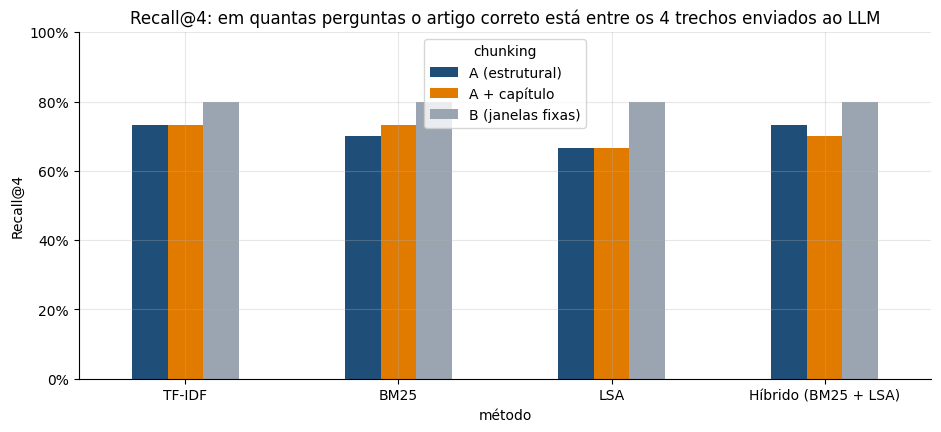

In [10]:
# Recall@4 de cada combinação
tabela = resultados["Recall@4"].unstack(0)[list(CHUNKS)]
ax = tabela.loc[METODOS].plot(kind="bar", color=[AZUL, LARANJA, CINZA], figsize=(11, 4.5))
ax.set_title("Recall@4: em quantas perguntas o artigo correto está entre os 4 trechos enviados ao LLM")
ax.set_ylabel("Recall@4")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

In [11]:
# Configuração escolhida: a melhor entre as estratégias estruturais, que permitem citar o artigo exato
estruturais = resultados.loc[["A (estrutural)", "A + capítulo"]]
melhor_estrategia, melhor_metodo = estruturais["MRR"].idxmax()
buscador_final = buscadores[melhor_estrategia]
print(f"Melhor configuração: chunking {melhor_estrategia} com {melhor_metodo}\n")
for _, linha in avaliacao.iterrows():
    top4 = buscador_final.buscar(linha["pergunta"], melhor_metodo, k=4)["artigo"].tolist()
    encontrados = {a for trecho in top4 for a in trecho.split("|")}
    if not encontrados & set(linha["artigos_corretos"]):
        print(f"- {linha['pergunta']}\n  correto: Art. {', '.join(linha['artigos_corretos'])} | encontrados: {top4}")

Melhor configuração: chunking A (estrutural) com Híbrido (BM25 + LSA)

- A empresa precisa avisar alguém quando acontece um vazamento de dados?
  correto: Art. 48 | encontrados: ['52', '6', '32', '43']
- Quando os dados pessoais devem ser apagados?
  correto: Art. 15, 16 | encontrados: ['58-B', '32', '43', '4']
- Quando é permitido enviar dados pessoais para outro país?
  correto: Art. 33 | encontrados: ['5', '31', '4', '34']
- A lei se aplica a empresas estrangeiras que tratam dados de pessoas no Brasil?
  correto: Art. 3 | encontrados: ['61', '4', '52', '5']
- O que é a ANPD?
  correto: Art. 55-A | encontrados: ['55-G', '55-K', '55-I', '55-J']
- Como órgãos públicos podem tratar dados pessoais?
  correto: Art. 23 | encontrados: ['21', '5', '55-K', '26']
- O que significa tratamento de dados?
  correto: Art. 5 | encontrados: ['43', '6', '3', '6']
- Qual a diferença entre controlador e operador?
  correto: Art. 5 | encontrados: ['19', '37', '39', '42']


### Conclusões

- As **janelas fixas** (estratégia B) tiveram o maior Recall@4 (80%), mas por um motivo enganoso: cada janela mistura em média quase dois artigos e as janelas se sobrepõem, o que aumenta as chances de "acertar". Em compensação, elas cortam frases ao meio e **não permitem citar o artigo exato**, o que é essencial em um assistente jurídico.
- Por isso, escolho a melhor configuração **estrutural**: um trecho por artigo com a **busca híbrida (BM25 + LSA)**, com Recall@4 de 73% e MRR de 0,64.
- Acrescentar o **título do capítulo** não ajudou: os títulos são genéricos, como "Do Tratamento de Dados Pessoais", e repetem as mesmas palavras em muitos trechos. É um resultado negativo, mas útil: nem toda ideia intuitiva melhora a busca, e só a avaliação mostra isso.
- Os erros seguem um padrão claro: **a pergunta usa palavras do dia a dia, e a lei usa termos técnicos**. Quem pergunta sobre "vazamento" não encontra "incidente de segurança"; quem quer "apagar" dados não encontra "eliminação".

### Melhoria: expandir a pergunta com um glossário

Muitos erros acontecem porque as pessoas usam palavras do dia a dia, e a lei usa termos técnicos: quem pergunta sobre **vazamento** não encontra o artigo que fala de **incidente de segurança**; quem quer **apagar** dados não encontra **eliminação**. Uma solução simples e transparente é um **glossário** que acrescenta à pergunta o termo jurídico correspondente.

**Cuidado com o vazamento de informação na avaliação:** criei o glossário depois de ver os erros acima, então a melhora nessas 30 perguntas fica otimista. Para uma medida justa, escrevi **10 perguntas novas**, depois de criar o glossário, e avalio a busca nelas também.

In [12]:
GLOSSARIO = {
    r"vazament|vazou|hacker|expost": "incidente de segurança",
    r"apag|exclu|delet|guardar|tempo": "eliminação eliminados término do tratamento",
    r"outro país|exterior|fora do brasil": "transferência internacional",
    r"algoritmo|automátic": "decisões tratamento automatizado",
    r"multa|puni|penalidade|violar": "sanções administrativas",
    r"governo|órgãos públicos": "poder público pessoas jurídicas de direito público",
    r"estrangeir": "território nacional",
    r"reportag|jornal": "fins exclusivamente jornalísticos",
    r"saúde|religião|biométric|genétic": "dado pessoal sensível",
    r"pais|responsável legal": "consentimento específico",
    r"pesquisa": "órgão de pesquisa estudos",
}


def expandir(pergunta):
    """Acrescenta à pergunta os termos jurídicos correspondentes às palavras do dia a dia."""
    extras = [termo for padrao, termo in GLOSSARIO.items() if re.search(padrao, pergunta.lower())]
    return pergunta + " " + " ".join(extras)


print(expandir("A empresa precisa avisar alguém quando acontece um vazamento de dados?"))

A empresa precisa avisar alguém quando acontece um vazamento de dados? incidente de segurança


In [13]:
# 10 perguntas novas, escritas depois de criar o glossário, para uma avaliação justa
NOVAS_PERGUNTAS = pd.DataFrame([
    ("Uma loja sofreu um ataque hacker e os dados dos clientes ficaram expostos. O que ela deve fazer?", ["48"]),
    ("Posso pedir para uma loja excluir meus dados do cadastro?", ["18", "16"]),
    ("Uma empresa pode guardar dados de clientes em servidores fora do Brasil?", ["33"]),
    ("O governo pode usar meus dados pessoais sem me perguntar?", ["23", "7"]),
    ("Que punição uma empresa pode receber por violar a lei?", ["52"]),
    ("Preciso de autorização dos pais para coletar dados de uma criança?", ["14"]),
    ("A informação sobre a minha religião é um dado sensível?", ["5", "11"]),
    ("Um sistema automático negou meu crédito. Posso pedir uma explicação?", ["20"]),
    ("Dados usados em pesquisas científicas precisam de consentimento?", ["7", "11", "13"]),
    ("Por quanto tempo a empresa pode guardar meus dados?", ["15", "16"]),
], columns=["pergunta", "artigos_corretos"])

comparacao = pd.DataFrame({
    ("30 perguntas originais", "sem glossário"): avaliar_busca(buscador_final, melhor_metodo),
    ("30 perguntas originais", "com glossário"): avaliar_busca(buscador_final, melhor_metodo, expandir_pergunta=True),
    ("10 perguntas novas", "sem glossário"): avaliar_busca(buscador_final, melhor_metodo, NOVAS_PERGUNTAS),
    ("10 perguntas novas", "com glossário"): avaliar_busca(buscador_final, melhor_metodo, NOVAS_PERGUNTAS, True),
}).T
comparacao.round(3)

Recall@1  Recall@4  Recall@10    MRR
30 perguntas originais sem glossário     0.533     0.733      0.967  0.635
                       com glossário     0.667     0.900      1.000  0.768
10 perguntas novas     sem glossário     0.300     0.500      0.500  0.375
                       com glossário     0.700     0.800      1.000  0.787

### Conclusões

- Nas 30 perguntas originais, o glossário elevou o **Recall@4 de 73% para 90%** e o MRR de 0,64 para 0,77.
- Nas **10 perguntas novas**, que o glossário nunca viu, o ganho foi ainda maior: **Recall@4 de 50% para 80%** e MRR de 0,38 para 0,79. Isso mostra que a melhora não é só um ajuste às perguntas de teste.
- O glossário é simples, barato e transparente: em uma empresa, ele poderia ser mantido pela própria equipe jurídica ou de privacidade. A busca final usa a configuração estrutural com o glossário.

[Voltar ao Índice](#back)

## Etapa 6. Geração da resposta com um LLM <a id='generation'></a>

Com os 4 trechos mais relevantes, monto as instruções para o LLM. As regras são o coração do RAG:

1. Responder **apenas com base nos trechos** enviados
2. **Citar o artigo** de cada informação, no formato (Art. X)
3. Se a resposta não estiver nos trechos, **dizer que não encontrou**, em vez de inventar
4. Usar linguagem simples, para quem não é da área jurídica

O notebook funciona com dois provedores de LLM, e usa o que tiver uma chave configurada:

- **Gemini**, do Google, que tem um plano gratuito: chave com o nome `GEMINI_API_KEY`
- **Claude**, da Anthropic: chave com o nome `ANTHROPIC_API_KEY`

No Google Colab, salve a chave no ícone de chave (🔑, "Secrets") da barra lateral, com o nome correspondente, e ative o acesso do notebook a ela. As instruções e a avaliação são as mesmas para os dois provedores.

In [14]:
MODELO_LLM = "claude-haiku-5-5"  # Modelo do Claude, usado se a chave configurada for da Anthropic

INSTRUCOES = """Você é um assistente que responde perguntas sobre a LGPD (Lei nº 13.709/2018).
Regras:
1. Responda usando APENAS os trechos da lei fornecidos.
2. Cite o artigo de cada informação no formato (Art. X).
3. Se os trechos não contiverem a resposta, diga apenas: "Não encontrei essa informação nos trechos da LGPD consultados."
4. Use linguagem simples, para quem não é da área jurídica, em no máximo 5 frases."""


def montar_contexto(pergunta, k=4):
    trechos = buscador_final.buscar(expandir(pergunta), melhor_metodo, k=k)  # Busca com a pergunta expandida
    contexto = "\n\n".join(f"[Art. {t.artigo}] {t.texto}" for t in trechos.itertuples())
    return f"Trechos da LGPD:\n{contexto}\n\nPergunta: {pergunta}", trechos["artigo"].tolist()


def obter_chave(nome):
    """Lê a chave de API da variável de ambiente ou dos Secrets do Google Colab."""
    chave = os.environ.get(nome)
    if chave is None:
        try:
            from google.colab import userdata
            chave = userdata.get(nome)
        except Exception:
            pass
    return chave


MODELO_GEMINI = "gemini-3.8-flash"  # Troque se o Google disponibilizar uma versão mais nova
PROVEDOR, cliente_llm = None, None
if obter_chave("GEMINI_API_KEY"):
    from google import genai
    from google.genai import types
    cliente_llm = genai.Client(api_key=obter_chave("GEMINI_API_KEY"))
    PROVEDOR = "Gemini"
elif obter_chave("ANTHROPIC_API_KEY"):
    import anthropic
    cliente_llm = anthropic.Anthropic(api_key=obter_chave("ANTHROPIC_API_KEY"))
    PROVEDOR = "Claude"

if PROVEDOR:
    print(f"Chave encontrada: as respostas serão geradas pelo {PROVEDOR}.")
else:
    print("Chave de API não encontrada: o notebook mostrará os trechos encontrados, sem gerar a resposta.")


import time

# O plano gratuito do Gemini aceita poucas requisições por minuto (5, no momento em que este notebook foi escrito).
# Por isso, o notebook espera um intervalo mínimo entre as chamadas. Com plano pago ou com o Claude, pode ser 0.
INTERVALO_MINIMO = 13 if PROVEDOR == "Gemini" else 0
_ultima_chamada = 0.0


def gerar(mensagem, tentativas=6):
    """Envia a mensagem ao LLM respeitando o limite de requisições e tenta de novo em caso de sobrecarga."""
    global _ultima_chamada
    espera = 15
    for tentativa in range(1, tentativas + 1):
        pausa = INTERVALO_MINIMO - (time.time() - _ultima_chamada)
        if pausa > 0:
            time.sleep(pausa)
        _ultima_chamada = time.time()
        try:
            return _gerar(mensagem)
        except Exception as erro:
            texto = str(erro)
            temporario = any(codigo in texto for codigo in ["429", "500", "503", "overloaded", "UNAVAILABLE", "RESOURCE_EXHAUSTED"])
            if not temporario or tentativa == tentativas:
                raise
            # Se a API informar quanto tempo esperar ("retry in 28s"), usa esse valor
            sugerido = re.search(r"retry in ([\d.]+)s", texto)
            aguardar = float(sugerido.group(1)) + 2 if sugerido else espera
            print(f"Limite ou sobrecarga da API (tentativa {tentativa}). Nova tentativa em {aguardar:.0f} segundos...")
            time.sleep(aguardar)
            espera = min(espera * 2, 90)


def _gerar(mensagem):
    """Envia as instruções e a mensagem ao LLM configurado e devolve o texto da resposta."""
    if PROVEDOR == "Gemini":
        resposta = cliente_llm.models.generate_content(
            model=MODELO_GEMINI, contents=mensagem,
            config=types.GenerateContentConfig(system_instruction=INSTRUCOES, max_output_tokens=400, temperature=0))
        return resposta.text
    resposta = cliente_llm.messages.create(model=MODELO_LLM, max_tokens=400, system=INSTRUCOES,
                                           messages=[{"role": "user", "content": mensagem}])
    return resposta.content[0].text


def responder(pergunta, k=4):
    """Busca os trechos e, se houver chave de API, gera a resposta com o LLM."""
    mensagem, artigos_usados = montar_contexto(pergunta, k)
    if cliente_llm is None:
        return None, artigos_usados
    return gerar(mensagem), artigos_usados

Chave de API não encontrada: o notebook mostrará os trechos encontrados, sem gerar a resposta.


In [15]:
# Exemplo completo: o que o LLM recebe e o que ele responde
pergunta = "A empresa precisa avisar alguém quando acontece um vazamento de dados?"
mensagem, artigos_usados = montar_contexto(pergunta)
print("O QUE O LLM RECEBE (resumido):\n")
print(mensagem[:900] + " [...]\n")
resposta, _ = responder(pergunta)
print("RESPOSTA:\n")
print(resposta if resposta else f"(sem chave de API) Trechos que seriam enviados: Art. {', '.join(artigos_usados)}")

O QUE O LLM RECEBE (resumido):

Trechos da LGPD:
[Art. 48] Art. 48. O controlador deverá comunicar à autoridade nacional e ao titular a ocorrência de incidente de segurança que possa acarretar risco ou dano relevante aos titulares. [...] § 3º No juízo de gravidade do incidente, será avaliada eventual comprovação de que foram adotadas medidas técnicas adequadas que tornem os dados pessoais afetados ininteligíveis, no âmbito e nos limites técnicos de seus serviços, para terceiros não autorizados a acessá-los.

[Art. 48] Art. 48. O controlador deverá comunicar à autoridade nacional e ao titular a ocorrência de incidente de segurança que possa acarretar risco ou dano relevante aos titulares. § 1º A comunicação será feita em prazo razoável, conforme definido pela autoridade nacional, e deverá mencionar, no mínimo: I - a descrição da natureza dos dados pessoais afetados; II - as informações sobre os titulares envolvidos; III [...]

RESPOSTA:

(sem chave de API) Trechos que seriam enviados: A

[Voltar ao Índice](#back)

## Etapa 7. Avaliação das respostas <a id='generation_eval'></a>

Avalio as respostas do LLM de duas formas automáticas:

1. **Citação correta:** nas 30 perguntas de avaliação, a resposta cita pelo menos um dos artigos corretos?
2. **Recusa correta:** em 5 perguntas **fora do escopo da LGPD**, o assistente diz que não encontrou a informação, em vez de inventar uma resposta?

Esta etapa só roda com uma chave de API configurada (Gemini ou Claude). No plano gratuito do Gemini, que limita as requisições por minuto, ela leva cerca de 8 minutos.

In [16]:
FORA_DO_ESCOPO = [
    "Qual é a alíquota máxima do imposto de renda para pessoas físicas?",
    "Quantos dias de férias um trabalhador CLT tem por ano?",
    "Qual é o prazo para trocar um produto com defeito pelo Código de Defesa do Consumidor?",
    "Qual é a velocidade máxima permitida em rodovias federais?",
    "Quem pode votar nas eleições brasileiras?",
]


def cita(resposta, artigos):
    """Verifica se a resposta cita algum dos artigos, no formato Art. X."""
    citados = set(re.findall(r"Art\.?\s*(\d+(?:-[A-Z])?)", resposta))
    return bool(citados & set(artigos))


if cliente_llm is None:
    print("Configure a chave de API para avaliar as respostas.")
else:
    linhas = []
    for _, linha in avaliacao.iterrows():
        resposta, usados = responder(linha["pergunta"])
        linhas.append({"pergunta": linha["pergunta"], "artigo_certo_na_busca": bool(set(usados) & set(linha["artigos_corretos"])),
                       "cita_artigo_correto": cita(resposta, linha["artigos_corretos"]), "resposta": resposta})
    respostas = pd.DataFrame(linhas)
    recusas = [("Não encontrei" in responder(p)[0]) for p in FORA_DO_ESCOPO]

    print(f"Respostas que citam um artigo correto: {respostas.cita_artigo_correto.mean():.0%}")
    print(f"... entre as perguntas em que a busca encontrou o artigo: "
          f"{respostas.loc[respostas.artigo_certo_na_busca, 'cita_artigo_correto'].mean():.0%}")
    print(f"Recusas corretas em perguntas fora do escopo: {np.mean(recusas):.0%} ({sum(recusas)} de {len(recusas)})")
    display(respostas[["pergunta", "resposta"]].head(5))

Configure a chave de API para avaliar as respostas.


### Como interpretar

- Se a busca encontra o artigo certo e o LLM o cita, o sistema está funcionando de ponta a ponta.
- Quando a busca falha, o LLM **não deve** inventar o artigo: o esperado é que ele responda só com o que recebeu ou diga que não encontrou.
- As recusas nas perguntas fora do escopo mostram se as instruções estão sendo seguidas, o que é essencial para um assistente confiável.

[Voltar ao Índice](#back)

## Conclusão geral <a id='end'></a>

Neste projeto, construí um assistente que responde perguntas sobre a LGPD com **RAG**: ele busca os artigos relevantes da lei e pede a um LLM que responda usando apenas esses artigos, citando a fonte.

**Principais resultados:**

- **Chunking:** dividir a lei por artigo (estratégia estrutural) é o que permite **citar o artigo exato**. As janelas fixas, comuns em tutoriais, encontram o assunto com um pouco mais de frequência, mas cortam frases e misturam artigos.
- **Busca:** a combinação de BM25 com análise semântica latente (LSA) teve o melhor desempenho entre as configurações estruturais. Acrescentar o título do capítulo não ajudou.
- **Glossário de termos:** a maior melhoria veio de traduzir palavras do dia a dia para os termos da lei. Em perguntas novas, o artigo correto passou a aparecer entre os 4 primeiros trechos em **80% dos casos, contra 50%** sem o glossário.
- **Geração:** o LLM recebe instruções para responder só com base nos trechos, citar os artigos e se recusar a responder o que não está na lei. A Etapa 7 mede automaticamente as citações corretas e as recusas em perguntas fora do escopo.

**Por que isso importa:** em temas jurídicos, uma resposta errada dita com confiança é pior do que nenhuma resposta. A avaliação sistemática de cada etapa é o que torna o assistente confiável o suficiente para uso real.

**Próximos passos:**

- Testar **embeddings multilíngues**, que captam o significado das frases, combinados com o BM25
- Acrescentar os **regulamentos da ANPD**, que detalham a lei em temas como incidentes de segurança e dosimetria das multas
- Criar uma **interface de chat**, por exemplo com Streamlit

[Voltar ao Índice](#back)